# Q8 Student performance

Using the given `student-mat.csv` dataset to predict final mathematics grade, G3, following the question's data and variable instructions.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

FEATURES = ['age', 'studytime', 'schoolsup', 'goout', 'health', 'absences', 'alc']
pd.set_option('display.precision', 6)
plt.rcParams.update({'font.size': 10, 'axes.spines.top': False, 'axes.spines.right': False})

DATA_PATH = Path("student-mat.csv")

OUTPUT_DIR = Path.cwd() / 'outputs'
OUTPUT_DIR.mkdir(exist_ok=True)


# to call for showing graphs with answers
def show_figure(fig, filename):
    path = OUTPUT_DIR / filename
    fig.savefig(path, dpi=180, bbox_inches='tight', facecolor='white')
    display(Image(filename=str(path)))
    plt.close(fig)

## (a)(i)–(ii) Data preparation

In [2]:
raw = pd.read_csv(DATA_PATH, sep=';')
data = raw[['age', 'studytime', 'schoolsup', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G3']].copy()
data['schoolsup'] = data['schoolsup'].map({'no': 0, 'yes': 1})
data['alc'] = (data['Dalc'] + data['Walc']) / 2
data = data.drop(columns=['Dalc', 'Walc'])[FEATURES + ['G3']]

display(data.head())
data.info()
display(data.describe().T)   # summary stats for each of the numeric columns
display(data.isna().sum().rename('Missing values').to_frame())  # to count missing entries

X = data[FEATURES]
y = data['G3']

,age,studytime,schoolsup,goout,health,absences,alc,G3
0,18,2,1,4,3,6,1.0,6
1,17,2,0,3,3,4,1.0,6
2,15,2,1,2,3,10,2.5,10
3,15,3,0,2,5,2,1.0,15
4,16,2,0,2,5,4,1.5,10


<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 8 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        395 non-null    int64  
 1   studytime  395 non-null    int64  
 2   schoolsup  395 non-null    int64  
 3   goout      395 non-null    int64  
 4   health     395 non-null    int64  
 5   absences   395 non-null    int64  
 6   alc        395 non-null    float64
 7   G3         395 non-null    int64  
dtypes: float64(1), int64(7)
memory usage: 24.8 KB


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
schoolsup,395.0,0.129114,0.335751,0.0,0.0,0.0,0.0,1.0
goout,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
health,395.0,3.554430,1.390303,1.0,3.0,4.0,5.0,5.0
absences,395.0,5.708861,8.003096,0.0,0.0,4.0,8.0,75.0
alc,395.0,1.886076,0.992195,1.0,1.0,1.5,2.5,5.0
G3,395.0,10.415190,4.581443,0.0,8.0,11.0,14.0,20.0


,Missing values
age,0
studytime,0
schoolsup,0
goout,0
health,0
absences,0
alc,0
G3,0


There are **395 observations**, seven predictors, and no missing values. G3 (student's final math grade) remains on its original 0–20 scale. The study-time and alcohol variables are ordinal scores (ordinal means ordered but the gaps between those points may not be equal).

## (a)(iii) Outliers

I flag values outside $[Q_1-1.5IQR,\ Q_3+1.5IQR]$, where $IQR=Q_3-Q_1$.

,Q1,Q3,IQR,Lower fence,Upper fence,Flagged count
age,16.0,18.0,2.0,13.00,21.00,1
studytime,1.0,2.0,1.0,-0.50,3.50,27
schoolsup,0.0,0.0,0.0,0.00,0.00,51
goout,2.0,4.0,2.0,-1.00,7.00,0
health,3.0,5.0,2.0,0.00,8.00,0
absences,0.0,8.0,8.0,-12.00,20.00,15
alc,1.0,2.5,1.5,-1.25,4.75,9


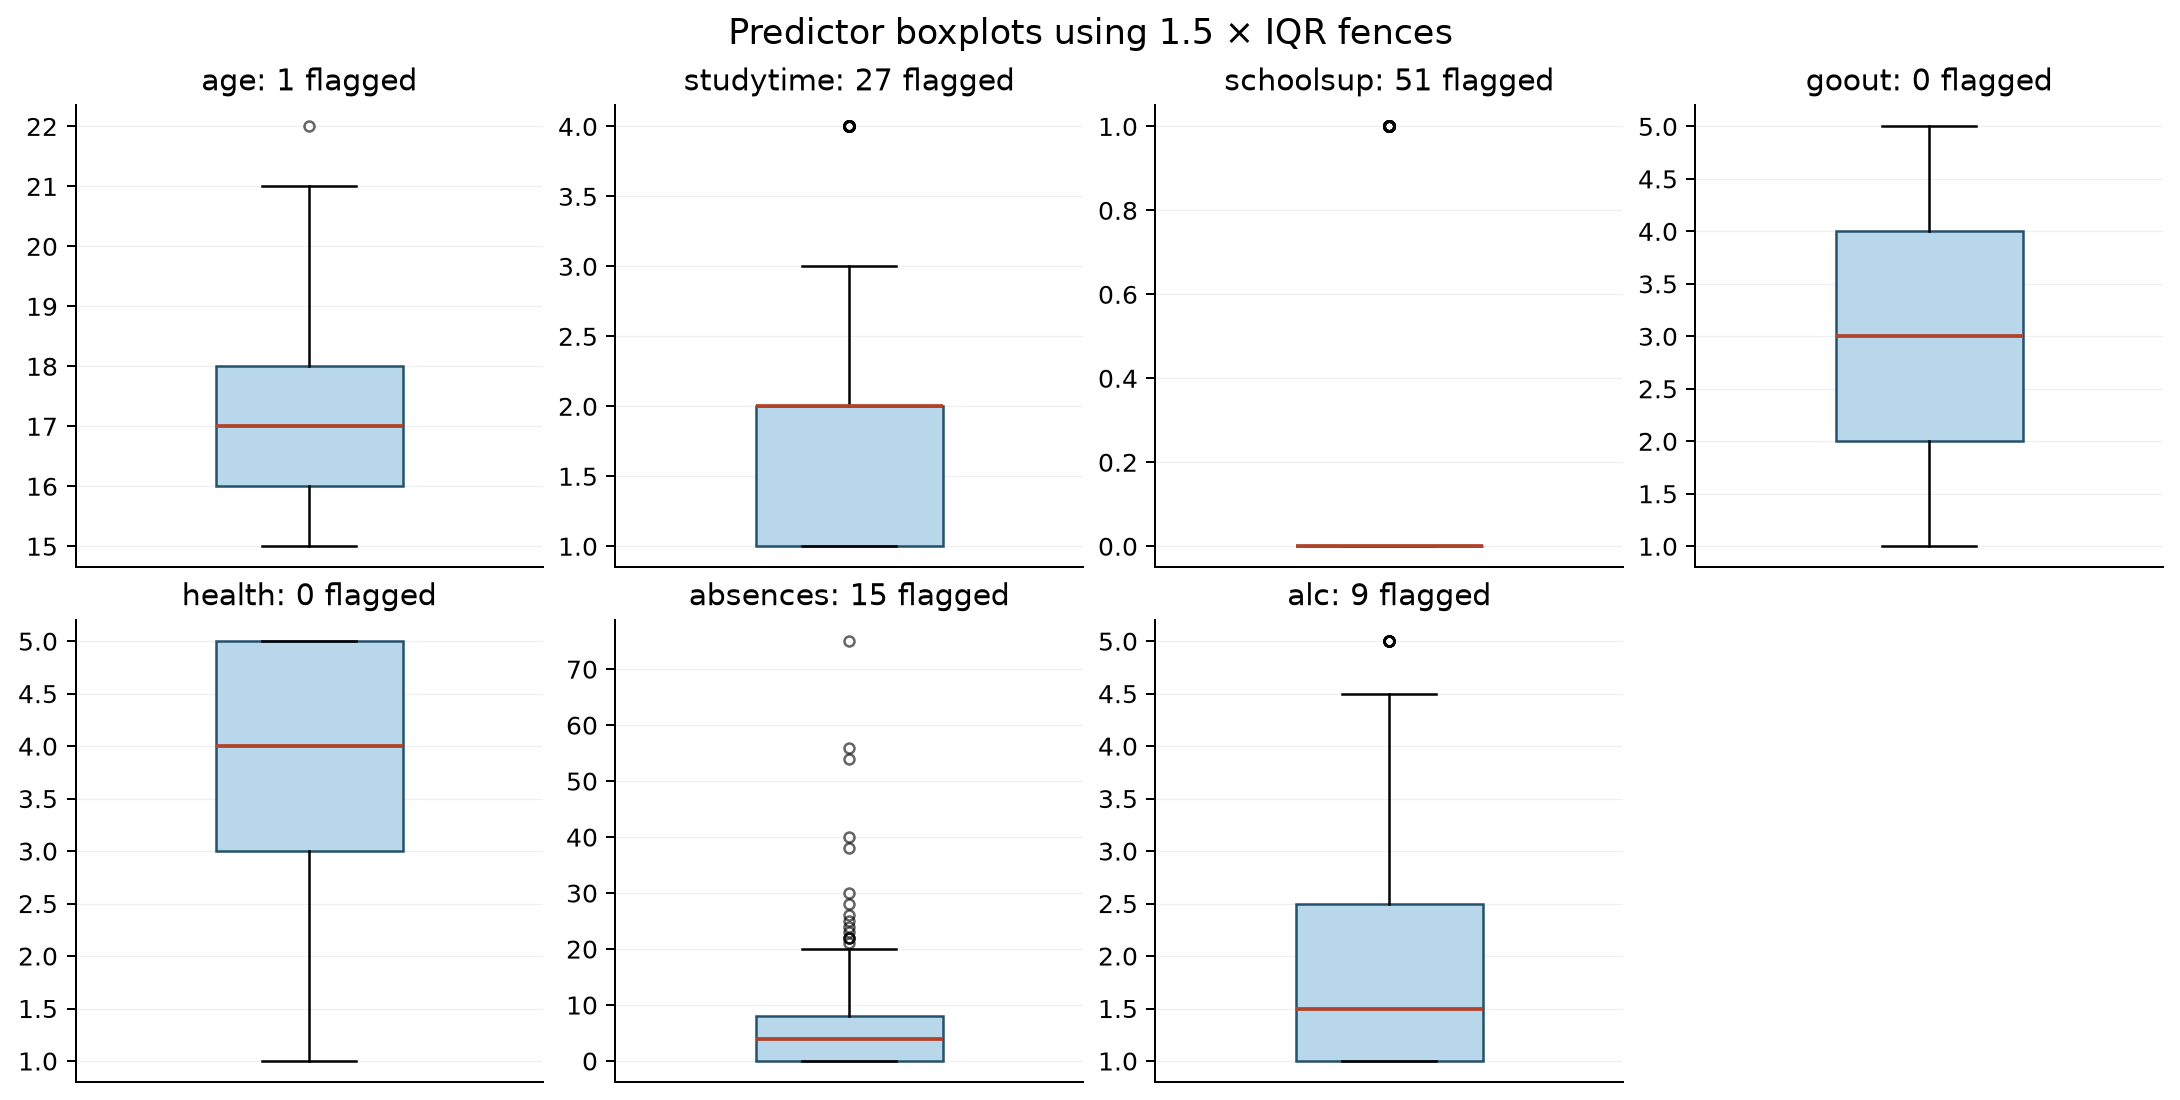

In [3]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
flags = X.lt(lower) | X.gt(upper)
outliers = pd.DataFrame({'Q1': q1, 'Q3': q3, 'IQR': iqr,
                         'Lower fence': lower, 'Upper fence': upper,
                         'Flagged count': flags.sum()})
display(outliers)

fig, axes = plt.subplots(2, 4, figsize=(12, 6), constrained_layout=True)
for ax, feature in zip(axes.flat, FEATURES):
    ax.boxplot(X[feature], widths=0.4, patch_artist=True,
               boxprops={'facecolor': '#b9d7ea', 'edgecolor': '#24516b'},
               medianprops={'color': '#b0432b', 'linewidth': 1.5},
               flierprops={'marker': 'o', 'markersize': 4, 'alpha': 0.6})
    ax.set_title(f'{feature}: {int(flags[feature].sum())} flagged')
    ax.set_xticks([])
    ax.grid(axis='y', alpha=0.2)
axes.flat[-1].axis('off')
fig.suptitle('Predictor boxplots using 1.5 × IQR fences', fontsize=14)
show_figure(fig, '01_predictor_boxplots.png')

All 51 `schoolsup = 1` observations are flagged because this binary variable has IQR = 0. These are valid categories. I retain all rows; an IQR flag alone does not establish an error.

## (a)(iv) PCA and (b)(i) train/test split

I make the required split before fitting the scaler and PCA to avoid leakage. G3 is excluded from both transformations. The regressions use all seven standardized predictors.

Training: 316; test: 79


,Variance explained
PC1,0.237162
PC2,0.172210


,PC1,PC2
age,0.395818,-0.565044
studytime,-0.328915,-0.429514
schoolsup,-0.218677,0.584533
goout,0.505945,0.140045
health,0.064743,0.269321
absences,0.246995,-0.083381
alc,0.605099,0.235511


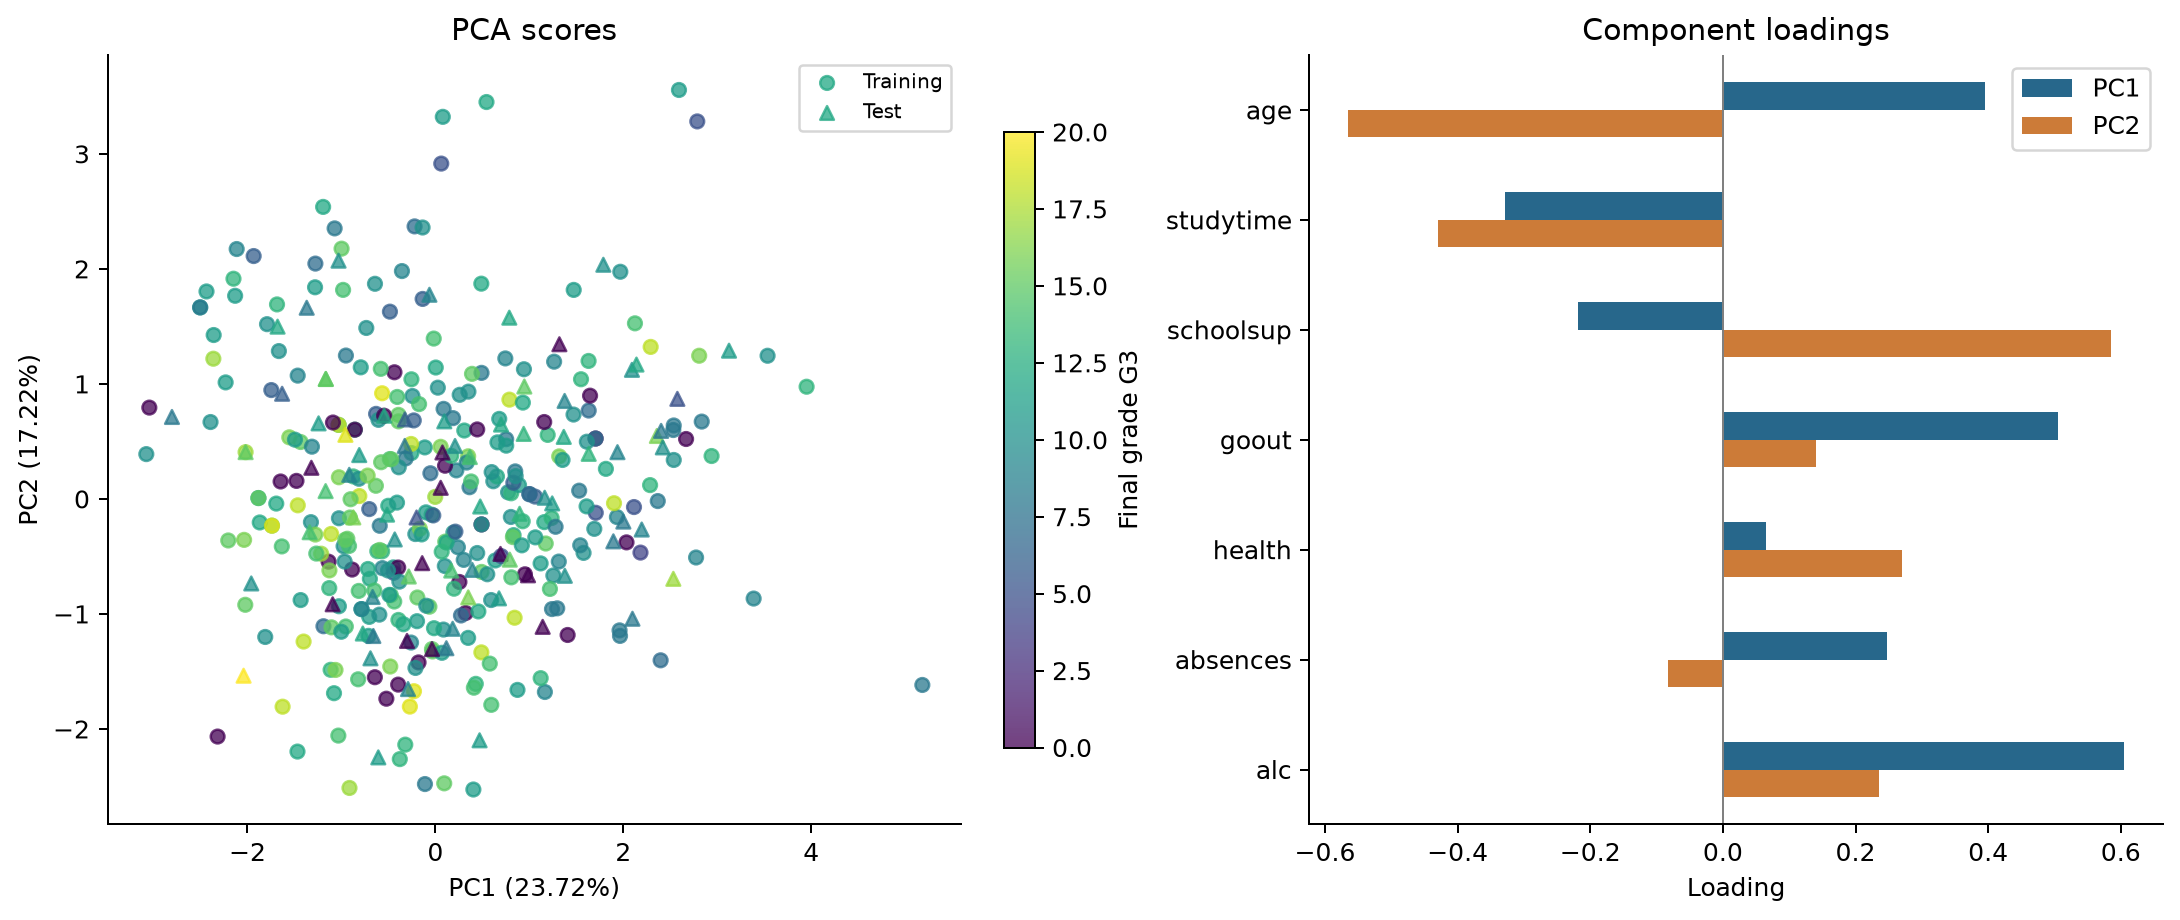

In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=552)
print(f'Training: {len(X_train)}; test: {len(X_test)}')

# Fit preprocessing on training data only.
scaler = StandardScaler()
X_train_z = scaler.fit_transform(X_train)
X_test_z = scaler.transform(X_test)
X_all_z = scaler.transform(X)

pca = PCA(n_components=2, svd_solver='full').fit(X_train_z)
# Project all observations onto the training-fitted component directions.
scores = pca.transform(X_all_z)
loadings = pd.DataFrame(pca.components_.T, index=FEATURES, columns=['PC1', 'PC2'])

display(pd.DataFrame({'Variance explained': pca.explained_variance_ratio_[:2]}, index=['PC1', 'PC2']))
display(loadings)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for idx, marker, label in [(X_train.index, 'o', 'Training'),
                            (X_test.index, '^', 'Test')]:
    points = axes[0].scatter(scores[idx, 0], scores[idx, 1], c=y.loc[idx],
                             cmap='viridis', vmin=0, vmax=20, marker=marker,
                             s=30, alpha=0.75, label=label)
axes[0].set(xlabel=f'PC1 ({pca.explained_variance_ratio_[0]:.2%})', ylabel=f'PC2 ({pca.explained_variance_ratio_[1]:.2%})', title='PCA scores')
axes[0].legend(fontsize=8)
fig.colorbar(points, ax=axes[0], label='Final grade G3', shrink=0.8)
loadings.plot.barh(ax=axes[1], color=['#27678b', '#cc7b38'])
axes[1].axvline(0, color='gray', linewidth=0.8)
axes[1].set(xlabel='Loading', ylabel='', title='Component loadings')
axes[1].invert_yaxis()
show_figure(fig, '02_pca.png')

PC1 and PC2 explain **23.72%** and **17.22%** of predictor variance, respectively (40.94% combined). By absolute loading, PC1 is driven mainly by **alc, goout, and age**; PC2 by **schoolsup, age, and studytime**. These percentages describe predictor variation, not variation explained in G3.

## (b)(ii) Models

In [5]:
models = {
    'OLS': LinearRegression(),
    'Ridge': Ridge(alpha=0.1),
    'Lasso': Lasso(alpha=0.1, max_iter=100000, tol=1e-10)
}
predictions = {}
for name, model in models.items():
    model.fit(X_train_z, y_train)
    predictions[name] = model.predict(X_test_z)

## (b)(iii) Test performance

In [6]:
rows = []
for name, pred in predictions.items():
    rows.append({
        'Model': name,
        'MAE': mean_absolute_error(y_test, pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, pred)),
        'R2': r2_score(y_test, pred)
    })
metrics = pd.DataFrame(rows).set_index('Model')
display(metrics)

,MAE,RMSE,R2
Model,,,
OLS,3.418009,4.755812,0.028177
Ridge,3.418064,4.755860,0.028157
Lasso,3.447338,4.794612,0.012255


**OLS has the lowest MAE and RMSE and the highest R²**, although its advantage over ridge is marginal (all three are almost equal for them). Lasso performs slightly worse at alpha = .1.

## (b)(iv) R² interpretation

Relative to predicting the test mean, OLS and ridge reduce squared error by approximately **2.82%**, and lasso by **1.23%**. The selected features explain little held-out grade variation; RMSE is about **4.8 grade points**.

## (b)(v) Coefficients

In [7]:
coefficients = pd.DataFrame({name: model.coef_ for name, model in models.items()}, index=FEATURES)
coefficients.loc['Intercept'] = [model.intercept_ for model in models.values()]
display(coefficients)

# Convert the binary coefficient to the change from no support to support.
j = FEATURES.index('schoolsup')
print(f'OLS predicted difference for schoolsup (0 to 1): {models["OLS"].coef_[j] / scaler.scale_[j]:.3f}')

,OLS,Ridge,Lasso
age,-0.785327,-0.784976,-0.630919
studytime,0.449134,0.448974,0.351270
schoolsup,-0.717780,-0.717459,-0.570052
goout,-0.570108,-0.569917,-0.477690
health,-0.245802,-0.245702,-0.141941
absences,0.197840,0.197726,0.070763
alc,0.036301,0.036145,-0.000000
Intercept,10.613924,10.613924,10.613924


OLS predicted difference for schoolsup (0 to 1): -2.035


This simply means that a student receiving school support (1) has a predicted final grade about 2.035 points lower than a student without support (0), holding the other predictors fixed.

## (b)(vi) Feature relationships

Holding the other predictors fixed, age, schoolsup, goout, and health have negative fitted associations with G3; studytime and absences have positive associations. The alc coefficient is near zero in OLS/ridge and exactly zero in lasso.

Each coefficient represents grade points per **one training standard deviation** of its predictor. For example, OLS associates a one-SD increase in studytime with **0.449 higher grade points**. A schoolsup change from 0 to 1 corresponds to **−2.035 points**. The intercept, **10.614**, is the prediction at the training predictor means.

These are associations, not causal effects. Students receiving support may already be struggling, and the positive absence coefficient does not establish that missing school improves grades like a cause and effect dynamic.

## (b)(vii) Regularization

With SSR denoting the sum of squared residuals, scikit-learn minimizes

$$
\text{Ridge: } SSR + \alpha \sum_j \beta_j^2
$$

$$
\text{Lasso: } \frac{SSR}{2n} + \alpha \sum_j |\beta_j|
$$

The intercept is unpenalized. Ridge shrinks coefficients and generally retains all predictors; lasso can set coefficients exactly to zero. Their different loss normalizations mean the same alpha does not represent equal penalty strength.

Here ridge is almost identical to OLS, while lasso removes alc. Neither improves test performance at the given alpha. The seven features provide limited linear predictive information; lasso's result suggests little additional contribution from alc at this penalty.

## (b)(viii) Increasing alpha

A larger alpha strengthens shrinkage, generally increasing bias and reducing variance. Test error may initially improve if overfitting decreases, but excessive shrinkage causes underfitting. MAE/RMSE and R² need not change monotonically. The way to go is by selecting alpha by cross-validation within the training data, fitting the scaler within each fold.

## (b)(ix) Feature engineering

- Trying `log1p(absences)` to capture a nonlinear attendance relationship.
- Adding studytime × absences or studytime × alc interaction terms.
- Comparing category indicators with the linear treatment of ordinal scores.
- If additional predictors are permitted, we could include prior failures or parental education. G1/G2 are candidates only when available at the intended prediction time.

and, we can evaluate these changes using training-set cross-validation.

## Residual analysis
#### visualizing it; outlier detection is done above in its section but i didn't know where to include this one.

OLS prediction range: 8.20 to 13.14
Test observations with G3 = 0: 11


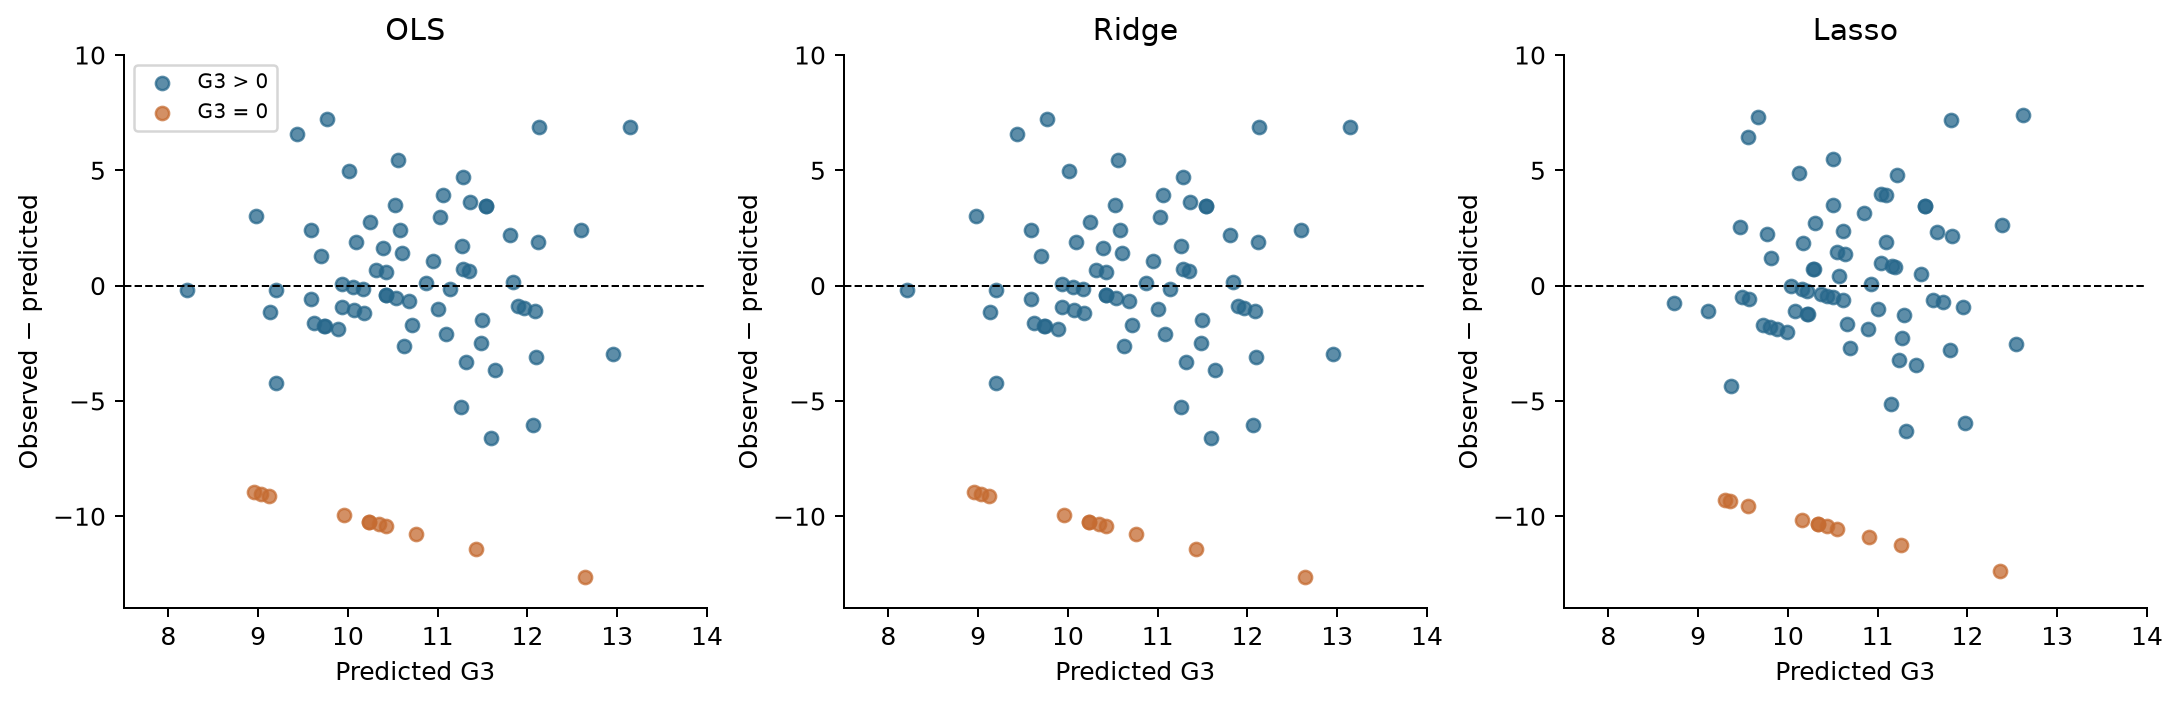

In [8]:
# first, the prediction ranges to interpret the graphs properly
print(f"OLS prediction range: {predictions['OLS'].min():.2f} to {predictions['OLS'].max():.2f}")
print("Test observations with G3 = 0:", (y_test == 0).sum())

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), constrained_layout=True)
zero_grade = y_test.to_numpy() == 0
for ax, (name, pred) in zip(axes, predictions.items()):
    residual = y_test.to_numpy() - pred
    for mask, color, label in [(~zero_grade, '#27678b', 'G3 > 0'),
                               (zero_grade, '#c56b31', 'G3 = 0')]:
        ax.scatter(pred[mask], residual[mask], color=color, s=28, alpha=0.75, label=label)
    ax.axhline(0, color='black', linestyle='--', linewidth=0.8)
    ax.set(title=name, xlabel='Predicted G3', ylabel='Observed − predicted', xlim=(7.5, 14), ylim=(-14, 10))
axes[0].legend(fontsize=8)
show_figure(fig, '03_residual_diagnostics.png')

OLS predictions range from **8.20 to 13.14**, missing much of the observed grade variation. The **11 test observations with G3 = 0** are overpredicted, and high grades are underpredicted. Logically, this concentration around the middle grades is consistent with the low test R².

#### graph + calculations for q1 boundary problem

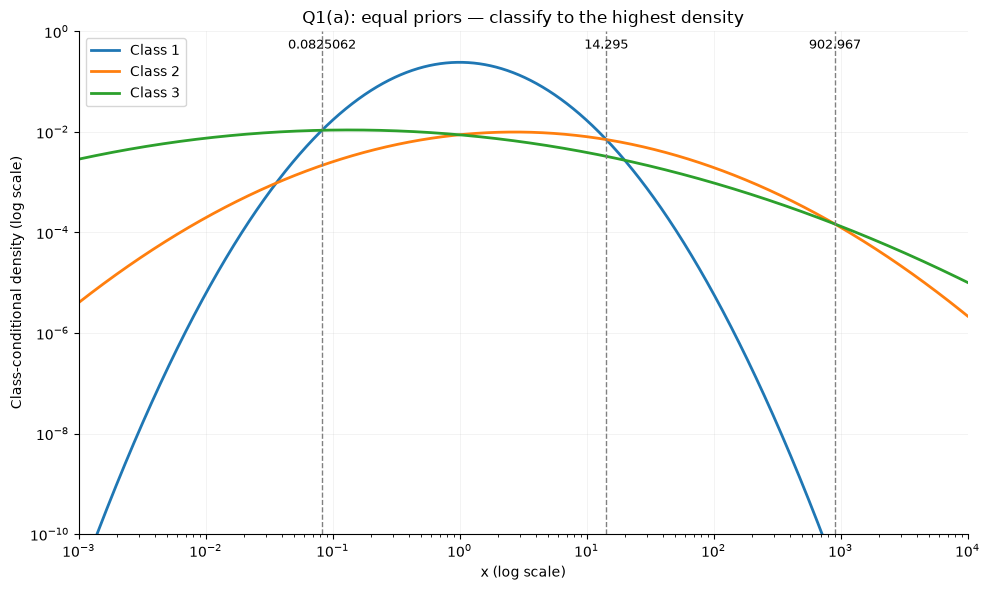

In [9]:
# ive already made the necessary imports earlier;

# Positive x values spanning all three classification boundaries.
x = np.logspace(-3, 4, 4000)

means = [1, 5, 7]   # given information
stds = [1, 2, 3]
colors = ["tab:blue", "tab:orange", "tab:green"]    # for intuitive understanding and clarity
fig, ax = plt.subplots(figsize=(10, 6))

for k, (mu, sigma, color) in enumerate(
    zip(means, stds, colors), start=1
):
    density = np.exp( -((np.log(x) - mu)**2) / (2 * sigma**2))
    density /= x * sigma * np.sqrt(2 * np.pi)

    ax.loglog(
        x, density,
        color=color,
        label=f"Class {k}",
        linewidth=2
    )

# Relevant roots calculation from the boundary equations.
z_boundaries = [
    (1 - np.sqrt(81 + 36*np.log(3))) / 4,
    (-1 + np.sqrt(64 + 24*np.log(2))) / 3,
    (17 + np.sqrt(144 + 360*np.log(3/2))) / 5,
]

for boundary in np.exp(z_boundaries):
    ax.axvline(
        boundary, color="gray",
        linestyle="--", linewidth=1
    )
    ax.text(
        boundary, 0.7, f"{boundary:.6g}",
        ha="center", va="top", fontsize=9
    )

ax.set(
    xlim=(1e-3, 1e4),
    ylim=(1e-10, 1),
    xlabel="x (log scale)",
    ylabel="Class-conditional density (log scale)",
    title="Q1(a): equal priors — classify to the highest density"
)
ax.legend()
ax.grid(which="major", alpha=0.2)

fig.tight_layout()
fig.savefig(
    "question1_density_plot.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)
plt.show()